# 4. CLIP and Diffusion Models

Practice for module 4: a toy CLIP trained with the symmetric contrastive loss on synthetic image/text
pairs, then zero-shot classification; and a toy diffusion model (DDPM) that learns to predict noise on
2D data with time conditioning and generates samples by iterative denoising.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True); e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

class Adam:
    def __init__(self, params, lr=1e-3, b1=0.9, b2=0.999):
        self.p, self.lr, self.b1, self.b2, self.t = params, lr, b1, b2, 0
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g * g
            p -= self.lr * (m / (1 - self.b1 ** self.t)) / (np.sqrt(v / (1 - self.b2 ** self.t)) + 1e-8)

## 4.1 Synthetic image-text pairs

10 hidden "concepts" (e.g. dog, cat, ...). An "image" is a 64-dim feature vector produced from the
concept plus image-specific nuisance factors; a "caption" is a 32-dim vector from the same concept plus
wording noise. The two modalities live in different spaces and must be aligned.

In [2]:
n_cls, d_img, d_txt, d_emb = 10, 64, 32, 16
concepts = rng.normal(size=(n_cls, 8))
A_img = rng.normal(size=(8, d_img)); N_img = rng.normal(size=(6, d_img))
A_txt = rng.normal(size=(8, d_txt))

def make_images(labels):
    return concepts[labels] @ A_img + rng.normal(size=(len(labels), 6)) @ N_img + 0.3 * rng.normal(size=(len(labels), d_img))
def make_texts(labels):
    return concepts[labels] @ A_txt + 0.5 * rng.normal(size=(len(labels), d_txt))

## 4.2 Contrastive training

Encoders are linear projections to a 16-dim joint space, outputs are L2-normalized, so `I · Tᵀ` is the
cosine-similarity matrix. With temperature τ the logits are `I·Tᵀ/τ`; the target is the identity matrix
(correct pairs on the diagonal) and the loss is cross-entropy over rows (image→text) and columns
(text→image), averaged.

zero-shot accuracy before training: 0.113 (chance = 0.1)
zero-shot accuracy after training:  1.000  (no labeled image was ever used)


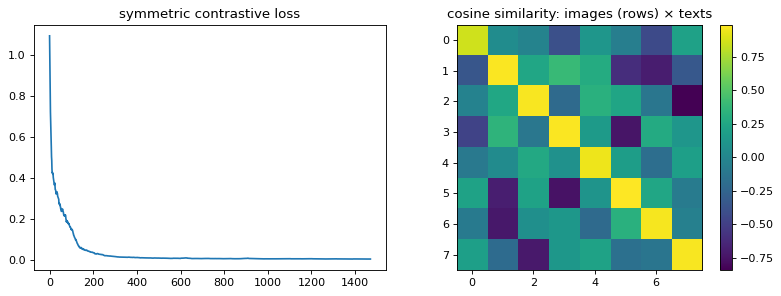

In [3]:
W_i = rng.normal(0, 1 / np.sqrt(d_img), (d_img, d_emb))
W_t = rng.normal(0, 1 / np.sqrt(d_txt), (d_txt, d_emb))
tau = 0.1
opt = Adam([W_i, W_t], lr=3e-3)

def normalize(u):
    n = np.linalg.norm(u, axis=1, keepdims=True); return u / n, n

def norm_backward(e, n, de):            # gradient through e = u / ||u||
    return (de - e * (de * e).sum(1, keepdims=True)) / n

def clip_step(imgs, txts):
    I, ni = normalize(imgs @ W_i); Tt, nt = normalize(txts @ W_t)
    logits = I @ Tt.T / tau
    B = len(imgs); Y = np.eye(B)
    Pi, Pt = softmax(logits, 1), softmax(logits, 0)
    loss = -(np.log(np.diag(Pi)).mean() + np.log(np.diag(Pt)).mean()) / 2
    dlogits = ((Pi - Y) + (Pt - Y)) / (2 * B)          # prediction - target, both directions
    dI, dT = dlogits @ Tt / tau, dlogits.T @ I / tau
    gWi = imgs.T @ norm_backward(I, ni, dI); gWt = txts.T @ norm_backward(Tt, nt, dT)
    return loss, [gWi, gWt], logits

def zero_shot_acc(n=1000):
    labels = rng.integers(n_cls, size=n)
    I, _ = normalize(make_images(labels) @ W_i)
    prompts = np.stack([make_texts(np.full(20, c)).mean(0) for c in range(n_cls)])   # "a photo of a <class>"
    Tc, _ = normalize(prompts @ W_t)
    return ((I @ Tc.T).argmax(1) == labels).mean()

print(f"zero-shot accuracy before training: {zero_shot_acc():.3f} (chance = {1 / n_cls})")
losses = []
for it in range(1500):
    labels = rng.permutation(n_cls)[:8]             # batch of 8 distinct concepts
    loss, grads, logits = clip_step(make_images(labels), make_texts(labels))
    opt.step(grads); losses.append(loss)
print(f"zero-shot accuracy after training:  {zero_shot_acc():.3f}  (no labeled image was ever used)")

labels = np.arange(8)
_, _, logits = clip_step(make_images(labels), make_texts(labels))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(np.convolve(losses, np.ones(30) / 30, "valid")); axes[0].set_title("symmetric contrastive loss")
im = axes[1].imshow(logits * tau, cmap="viridis"); axes[1].set_title("cosine similarity: images (rows) × texts")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

## 4.3 Temperature sharpens or softens the distribution

In [4]:
sims = np.array([0.9, 0.7, 0.3, 0.1])
for t in [1.0, 0.1, 0.01]:
    print(f"τ={t:5}: softmax(sim/τ) = {softmax(sims / t)}")

τ=  1.0: softmax(sim/τ) = [0.355 0.291 0.195 0.16 ]
τ=  0.1: softmax(sim/τ) = [0.879 0.119 0.002 0.   ]
τ= 0.01: softmax(sim/τ) = [1. 0. 0. 0.]


## 4.4 Diffusion: forward noising process

Data: points on a spiral. With a noise schedule `β_t`, `x_t = √ᾱ_t·x_0 + √(1-ᾱ_t)·ε`. At large t the data
becomes pure Gaussian noise.

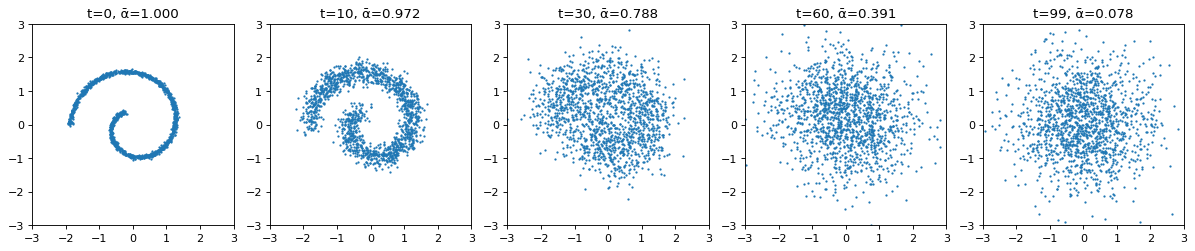

In [5]:
def spiral(n):
    t = np.sqrt(rng.uniform(0.05, 1, n)) * 3 * np.pi
    return np.c_[t * np.cos(t), t * np.sin(t)] / 5 + 0.03 * rng.normal(size=(n, 2))

x0_all = spiral(5000)
T = 100
betas = np.linspace(1e-4, 0.05, T)
alphas = 1 - betas
abar = np.cumprod(alphas)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, t in zip(axes, [0, 10, 30, 60, 99]):
    eps = rng.normal(size=x0_all.shape)
    xt = np.sqrt(abar[t]) * x0_all + np.sqrt(1 - abar[t]) * eps
    ax.scatter(*xt[:1500].T, s=1); ax.set_title(f"t={t}, ᾱ={abar[t]:.3f}")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## 4.5 Training a noise predictor with time conditioning

An MLP `ε_θ(x_t, t)` gets the noisy point plus a sinusoidal embedding of t (so it knows how much noise
there is) and is trained with the L2 loss between predicted and true noise. For images this network
would be a U-Net; for 2D points an MLP is enough.

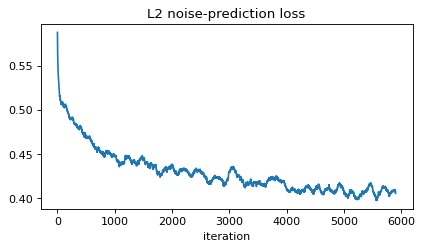

In [6]:
def t_embed(t, dim=16):
    freqs = np.exp(np.linspace(0, np.log(100), dim // 2))
    a = t[:, None] / T * freqs[None]
    return np.c_[np.sin(a), np.cos(a)]

def init(i, o): return rng.normal(0, np.sqrt(2 / i), (i, o)), np.zeros(o)
H = 128
(W1, b1), (W2, b2), (W3, b3) = init(2 + 16, H), init(H, H), init(H, 2)
net = [W1, b1, W2, b2, W3, b3]
opt = Adam(net, lr=2e-3)

def eps_model(x, t, cache=False):
    inp = np.c_[x, t_embed(t)]
    z1 = inp @ W1 + b1; a1 = np.maximum(0, z1)
    z2 = a1 @ W2 + b2; a2 = np.maximum(0, z2)
    out = a2 @ W3 + b3
    return (out, (inp, z1, a1, z2, a2)) if cache else out

losses = []
for it in range(6000):
    x0 = x0_all[rng.integers(len(x0_all), size=256)]
    t = rng.integers(T, size=256)
    eps = rng.normal(size=x0.shape)
    xt = np.sqrt(abar[t])[:, None] * x0 + np.sqrt(1 - abar[t])[:, None] * eps
    pred, (inp, z1, a1, z2, a2) = eps_model(xt, t, cache=True)
    losses.append(np.mean((pred - eps) ** 2))
    d3 = 2 * (pred - eps) / pred.size
    d2 = (d3 @ W3.T) * (z2 > 0); d1 = (d2 @ W2.T) * (z1 > 0)
    opt.step([inp.T @ d1, d1.sum(0), a1.T @ d2, d2.sum(0), a2.T @ d3, d3.sum(0)])
    if it == 4000: opt.lr = 5e-4

plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(100) / 100, "valid"))
plt.title("L2 noise-prediction loss"); plt.xlabel("iteration"); plt.show()

## 4.6 Generation by iterative denoising

Start from pure noise and run the reverse process for t = T-1 … 0:
`x_{t-1} = (x_t - β_t/√(1-ᾱ_t)·ε_θ(x_t, t)) / √α_t + σ_t z`. Structure appears gradually.

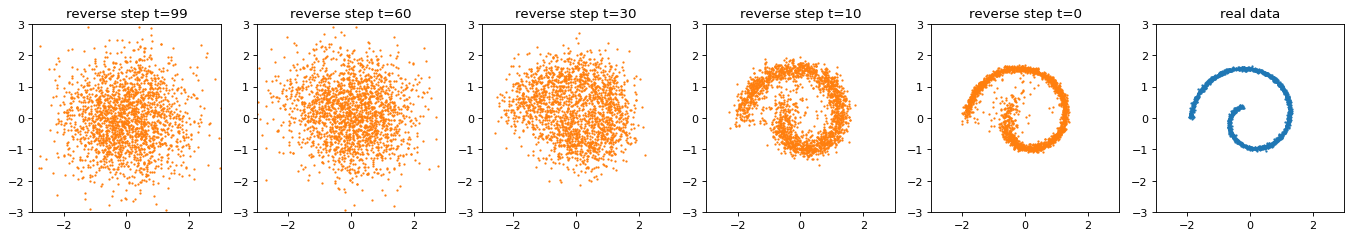

In [7]:
x = rng.normal(size=(2000, 2))
snapshots = {}
for t in reversed(range(T)):
    eps_hat = eps_model(x, np.full(len(x), t))
    x = (x - betas[t] / np.sqrt(1 - abar[t]) * eps_hat) / np.sqrt(alphas[t])
    if t > 0:
        x += np.sqrt(betas[t]) * rng.normal(size=x.shape)
    if t in (99, 60, 30, 10, 0): snapshots[t] = x.copy()

fig, axes = plt.subplots(1, 6, figsize=(17, 3))
for ax, (t, s) in zip(axes, snapshots.items()):
    ax.scatter(*s.T, s=1, c="C1"); ax.set_title(f"reverse step t={t}")
axes[5].scatter(*x0_all[:2000].T, s=1); axes[5].set_title("real data")
for ax in axes: ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()